<a href="https://colab.research.google.com/github/AK888-hp/ML-II_Lab/blob/main/kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
df = sns.load_dataset("penguins")

print("First five rows:")
print(df.head())


First five rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  


In [ ]:
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]
target = "species"

In [ ]:
df = df[features + [target]].dropna()

X = df[features]
y = df[target]


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

# 6. Map each cluster to its majority species
cluster_to_species = (
    df.groupby("cluster")[target]
    .agg(lambda values: values.mode().iloc[0])
    .to_dict()
)

df["predicted_species"] = df["cluster"].map(cluster_to_species)

print("\nCluster-to-species mapping:")
print(cluster_to_species)



Cluster-to-species mapping:
{0: 'Chinstrap', 1: 'Gentoo', 2: 'Adelie'}


In [ ]:
print("\nAccuracy:", round(
    accuracy_score(y, df["predicted_species"]) * 100, 2
), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y, df["predicted_species"],
    labels=["Adelie", "Chinstrap", "Gentoo"]
))

print("\nClassification Report:")
print(classification_report(
    y, df["predicted_species"], zero_division=0
))



Accuracy: 91.52 %

Confusion Matrix:
[[127  24   0]
 [  5  63   0]
 [  0   0 123]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.96      0.84      0.90       151
   Chinstrap       0.72      0.93      0.81        68
      Gentoo       1.00      1.00      1.00       123

    accuracy                           0.92       342
   macro avg       0.90      0.92      0.90       342
weighted avg       0.93      0.92      0.92       342



In [ ]:
print("\nSample predictions:")
print(df[[target, "cluster", "predicted_species"]].head(10))



Sample predictions:
   species  cluster predicted_species
0   Adelie        2            Adelie
1   Adelie        2            Adelie
2   Adelie        2            Adelie
4   Adelie        2            Adelie
5   Adelie        2            Adelie
6   Adelie        2            Adelie
7   Adelie        2            Adelie
8   Adelie        2            Adelie
9   Adelie        0         Chinstrap
10  Adelie        2            Adelie


In [ ]:
new_penguin = pd.DataFrame([{
    "bill_length_mm": 39.1,
    "bill_depth_mm": 18.7,
    "flipper_length_mm": 181,
    "body_mass_g": 3750
}])

In [ ]:
new_penguin_scaled = scaler.transform(new_penguin)

In [ ]:
new_cluster = kmeans.predict(new_penguin_scaled)[0]

In [ ]:
predicted_species = cluster_to_species[new_cluster]

In [ ]:
print("\n--- NEW PENGUIN CLASSIFICATION ---")
print("Input values:")
print(new_penguin)

print("Predicted cluster:", new_cluster)
print("Predicted species:", predicted_species)


--- NEW PENGUIN CLASSIFICATION ---
Input values:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            39.1           18.7                181         3750
Predicted cluster: 2
Predicted species: Adelie


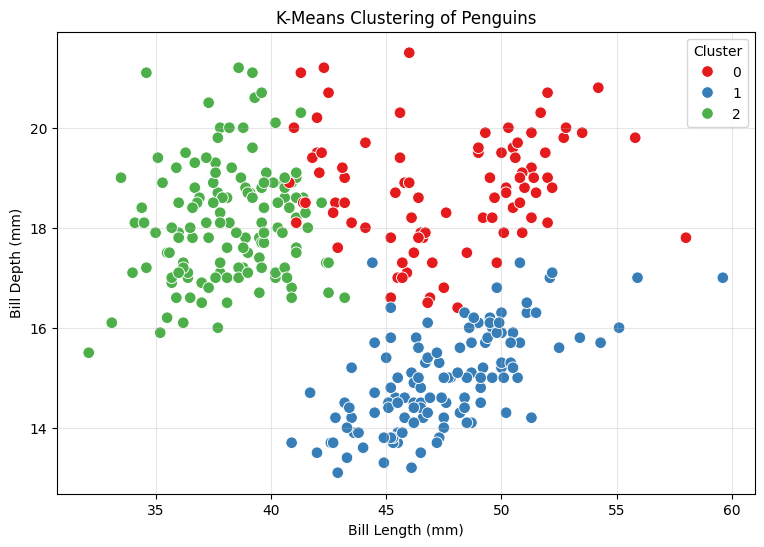

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="cluster",
    palette="Set1",
    s=70
)

plt.title("K-Means Clustering of Penguins")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

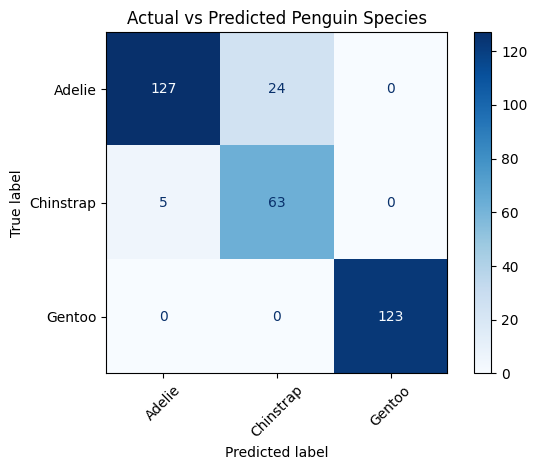

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y,
    df["predicted_species"],
    labels=["Adelie", "Chinstrap", "Gentoo"],
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Actual vs Predicted Penguin Species")
plt.tight_layout()
plt.show()

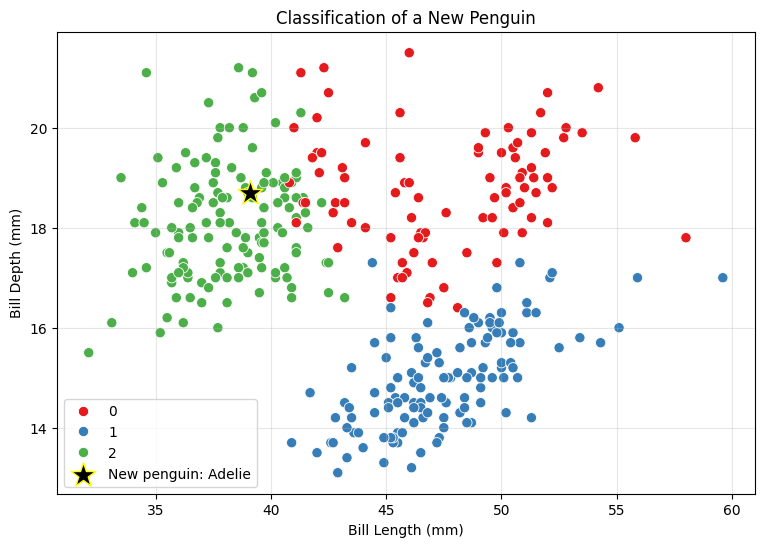

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="cluster",
    palette="Set1",
    s=55
)

plt.scatter(
    new_penguin["bill_length_mm"].iloc[0],
    new_penguin["bill_depth_mm"].iloc[0],
    color="black",
    marker="*",
    s=350,
    edgecolor="yellow",
    label=f"New penguin: {predicted_species}"
)

plt.title("Classification of a New Penguin")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Original Dataset:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


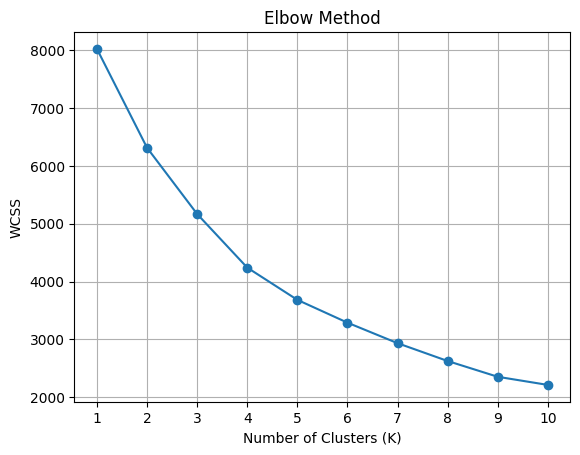


Cluster Assignments:
   survived     sex   age     fare  Cluster
0         0    male  22.0   7.2500        1
1         1  female  38.0  71.2833        0
2         1  female  26.0   7.9250        1
3         1  female  35.0  53.1000        1
4         0    male  35.0   8.0500        1
5         0    male   NaN   8.4583        2
6         0    male  54.0  51.8625        1
7         0    male   2.0  21.0750        1
8         1  female  27.0  11.1333        1
9         1  female  14.0  30.0708        0

Cluster Counts:
Cluster
1    646
0    168
2     77
Name: count, dtype: int64


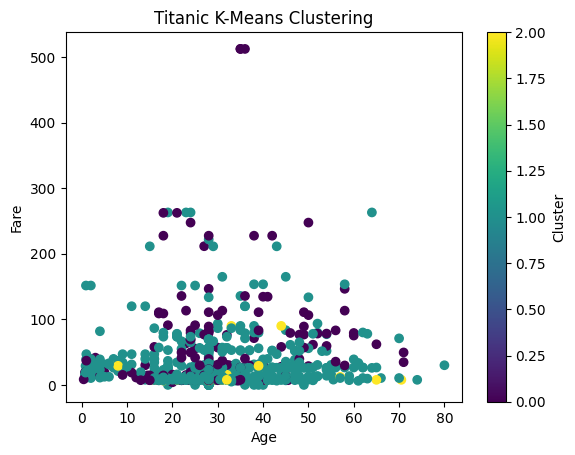

In [2]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load Titanic Dataset directly from Seaborn
df = sns.load_dataset('titanic')

print("Original Dataset:")
print(df.head())

# 2. Select Features
data = df[['pclass', 'sex', 'age', 'sibsp',
           'parch', 'fare', 'embarked']].copy()

# 3. Handle Missing Values
data['age'] = data['age'].fillna(data['age'].median())
data['embarked'] = data['embarked'].fillna(
    data['embarked'].mode()[0]
)

# 4. Convert Categorical Data into Numerical Data
data['sex'] = data['sex'].map({
    'male': 0,
    'female': 1
})

data = pd.get_dummies(data, columns=['embarked'], dtype=int)

# 5. Feature Scaling
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

# 6. Elbow Method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

# 7. Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid()
plt.show()

# 8. Apply K-Means (Example: K=3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(scaled_data)

# 9. Display Results
print("\nCluster Assignments:")
print(df[['survived', 'sex', 'age', 'fare', 'Cluster']].head(10))

print("\nCluster Counts:")
print(df['Cluster'].value_counts())

# 10. Visualize Clusters
plt.scatter(data['age'], data['fare'],
            c=df['Cluster'], cmap='viridis')

plt.title('Titanic K-Means Clustering')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.colorbar(label='Cluster')
plt.show()
